## Phase 1: Data Selection, Cleaning, and Exploratory Data Analysis (EDA)
### 1.1 Environment Setup & Data Loading

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
# Set a global random seed for reproducibility (Required by project guidelines)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure visualization style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Load the dataset
file_path = 'UCI_Credit_Card.csv'

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully from local file.")
else:
    print("Dataset file is not here :]")


Dataset loaded successfully from local file.


In [3]:
print(f"Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head()

Dataset Shape: 30,000 rows and 25 columns.


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


### 1.2 Data Cleaning
We drop the `ID` column, rename `PAY_0` to `PAY_1` and the target column to `DEFAULT`, remove duplicates, and group undocumented codes in `EDUCATION` (0, 5, 6 $\rightarrow$ 4) and `MARRIAGE` (0 $\rightarrow$ 3).

In [4]:
# 1. Drop ID and rename columns
df.drop(columns=['ID'], inplace=True)
df.rename(columns={'PAY_0': 'PAY_1', 'default.payment.next.month': 'DEFAULT'}, inplace=True)

In [5]:
# 2. Check missing values and remove duplicates
print("Missing values:", df.isnull().sum().sum())
print("Duplicates before:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

Missing values: 0
Duplicates before: 35


In [6]:
# 3. Clean undocumented values (Hidden missing values)
df['EDUCATION'].replace({0: 4, 5: 4, 6: 4}, inplace=True)
df['MARRIAGE'].replace({0: 3}, inplace=True)

print("EDUCATION counts:\n", df['EDUCATION'].value_counts())
print("\nMARRIAGE counts:\n", df['MARRIAGE'].value_counts())

EDUCATION counts:
 EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

MARRIAGE counts:
 MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64


**Cleaning Summary:**
* Removed the `ID` column and standardized column names (`PAY_1` and `DEFAULT`).
* Confirmed `0` missing values and removed `35` duplicate rows.
* Merged undocumented values in `EDUCATION` (`0, 5, 6`) into category `4` (Others) and in `MARRIAGE` (`0`) into category `3` (Others).
* **Outliers:** High values in `LIMIT_BAL`, `BILL_AMT`, and `PAY_AMT` were retained rather than removed because they represent valid high-credit clients rather than data entry errors. Their impact on scale-sensitive models will be handled using `StandardScaler` and `PowerTransformer` inside our modeling pipelines.

### 1.3 Exploratory Data Analysis (EDA)
#### A. Target Variable Distribution (`DEFAULT`)
We check the distribution of the target variable to quantify the class imbalance between non-defaulters (`0`) and defaulters (`1`).

DEFAULT
0    77.874187
1    22.125813
Name: proportion, dtype: float64


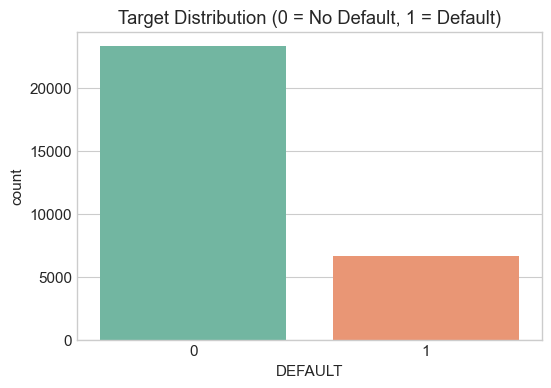

In [7]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='DEFAULT', palette='Set2')
plt.title('Target Distribution (0 = No Default, 1 = Default)')

# Print exact percentages
print(df['DEFAULT'].value_counts(normalize=True) * 100)
plt.show()

**Observation:** 
The dataset is imbalanced: **77.87%** of clients did not default (`0`), while **22.13%** defaulted (`1`). This confirms the need for `Stratified Train/Test Split`, `class_weight='balanced'`, and evaluating models using **Recall, Precision, F1-score, and ROC-AUC** rather than accuracy alone.

#### B. Demographic & Sensitive Attributes Analysis
We explore how default rates vary across sensitive demographic groups (`SEX`, `EDUCATION`, `MARRIAGE`, and `AGE`), which also establishes the baseline for our Phase 6 Fairness Audit.

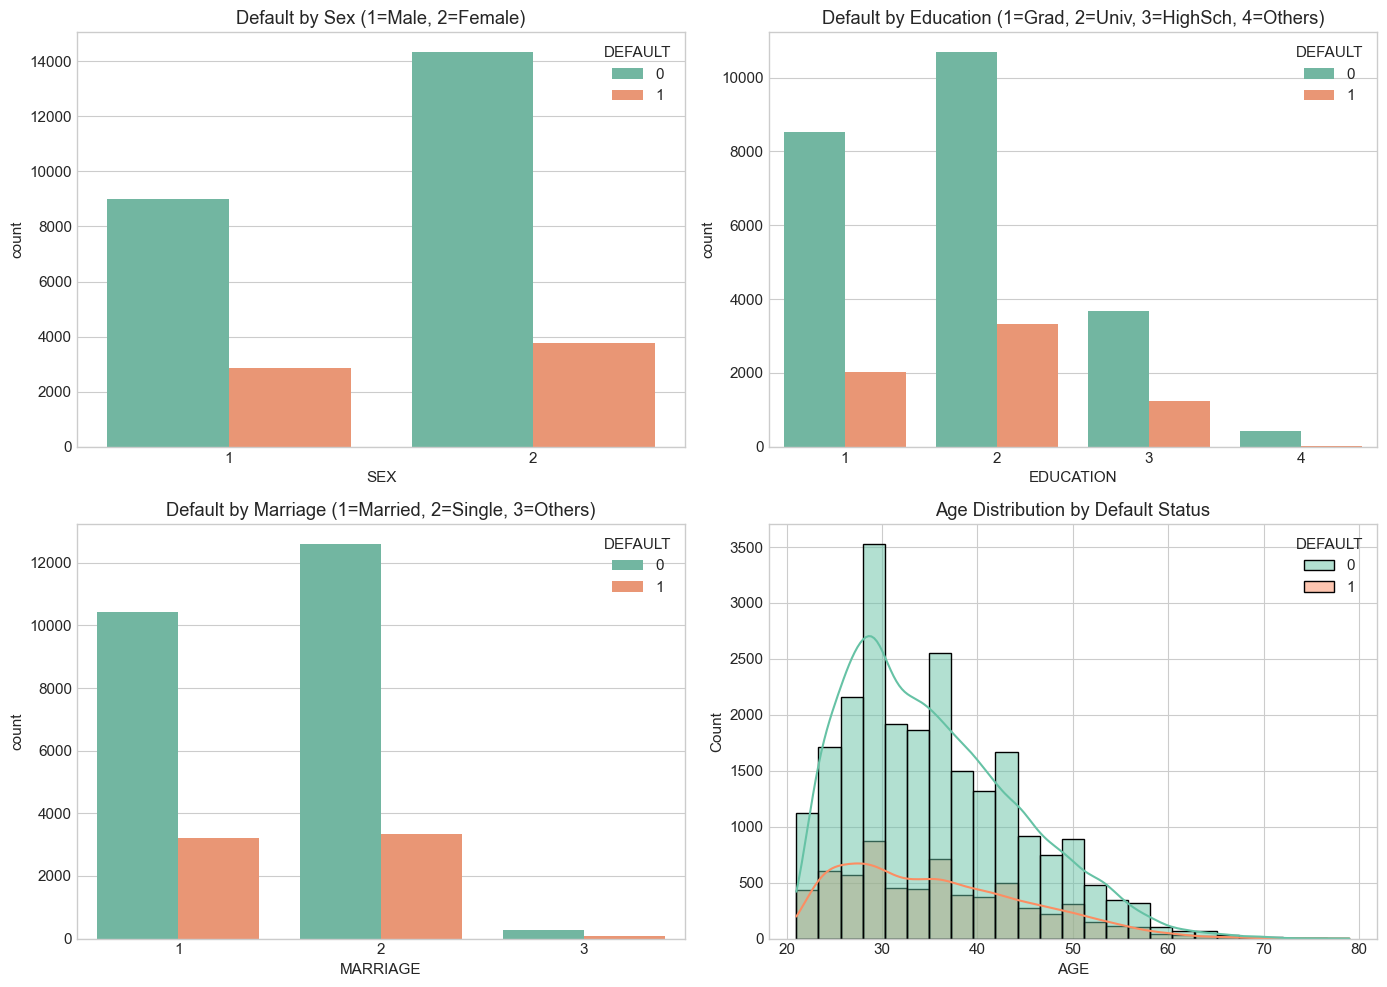


Default Rate (%) by SEX:
SEX
1    24.16
2    20.79
Name: DEFAULT, dtype: float64

Default Rate (%) by EDUCATION:
EDUCATION
1    19.24
2    23.74
3    25.17
4     7.05
Name: DEFAULT, dtype: float64

Default Rate (%) by MARRIAGE:
MARRIAGE
1    23.46
2    20.95
3    23.61
Name: DEFAULT, dtype: float64


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='SEX', hue='DEFAULT', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Default by Sex (1=Male, 2=Female)')

sns.countplot(data=df, x='EDUCATION', hue='DEFAULT', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('Default by Education (1=Grad, 2=Univ, 3=HighSch, 4=Others)')

sns.countplot(data=df, x='MARRIAGE', hue='DEFAULT', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('Default by Marriage (1=Married, 2=Single, 3=Others)')

sns.histplot(data=df, x='AGE', hue='DEFAULT', bins=25, kde=True, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Age Distribution by Default Status')

plt.tight_layout()
plt.show()

# Print exact default rate (%) per group for the report
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"\nDefault Rate (%) by {col}:")
    print((df.groupby(col)['DEFAULT'].mean() * 100).round(2))

**Observations:**
* **Sex (`SEX`):** Males (`1`) have a noticeably higher default rate (**~24.2%**) compared to females (`2`, **~20.8%**), indicating a potential demographic disparity to monitor during the Fairness Audit.
* **Education (`EDUCATION`):** Clients with high school (`3`) or university (`2`) education show higher default rates than graduate school (`1`) clients.
* **Marriage (`MARRIAGE`):** Married clients (`1`) exhibit a slightly higher default proportion than single clients (`2`).

#### C. Financial Features & Correlation Matrix
We examine the distribution of credit limits (`LIMIT_BAL`), repayment status (`PAY_1`), and the correlation matrix across all features to detect multicollinearity.

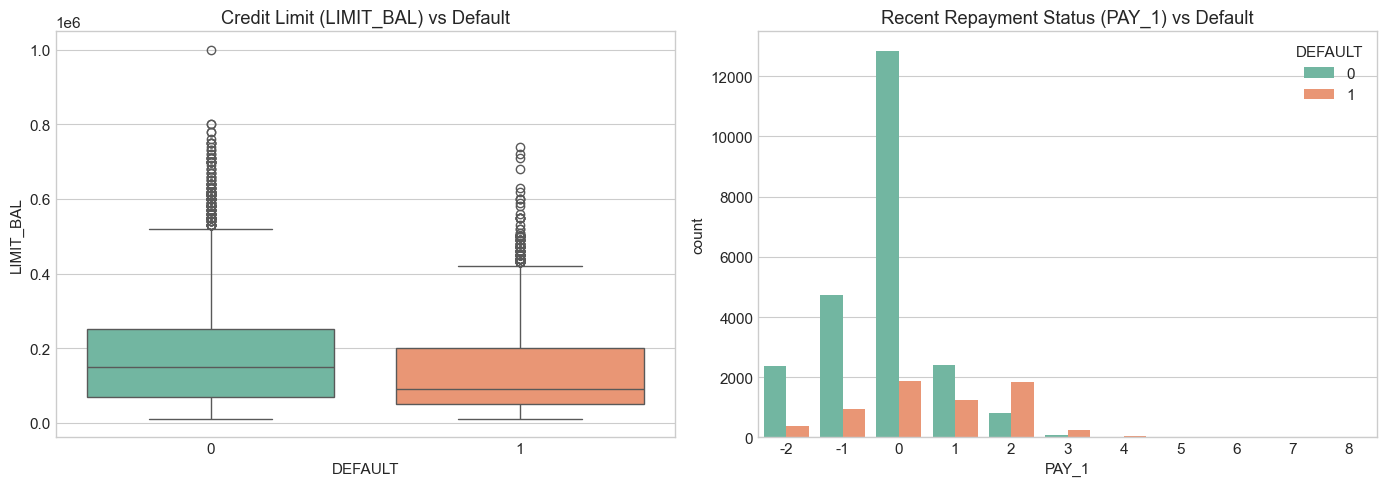

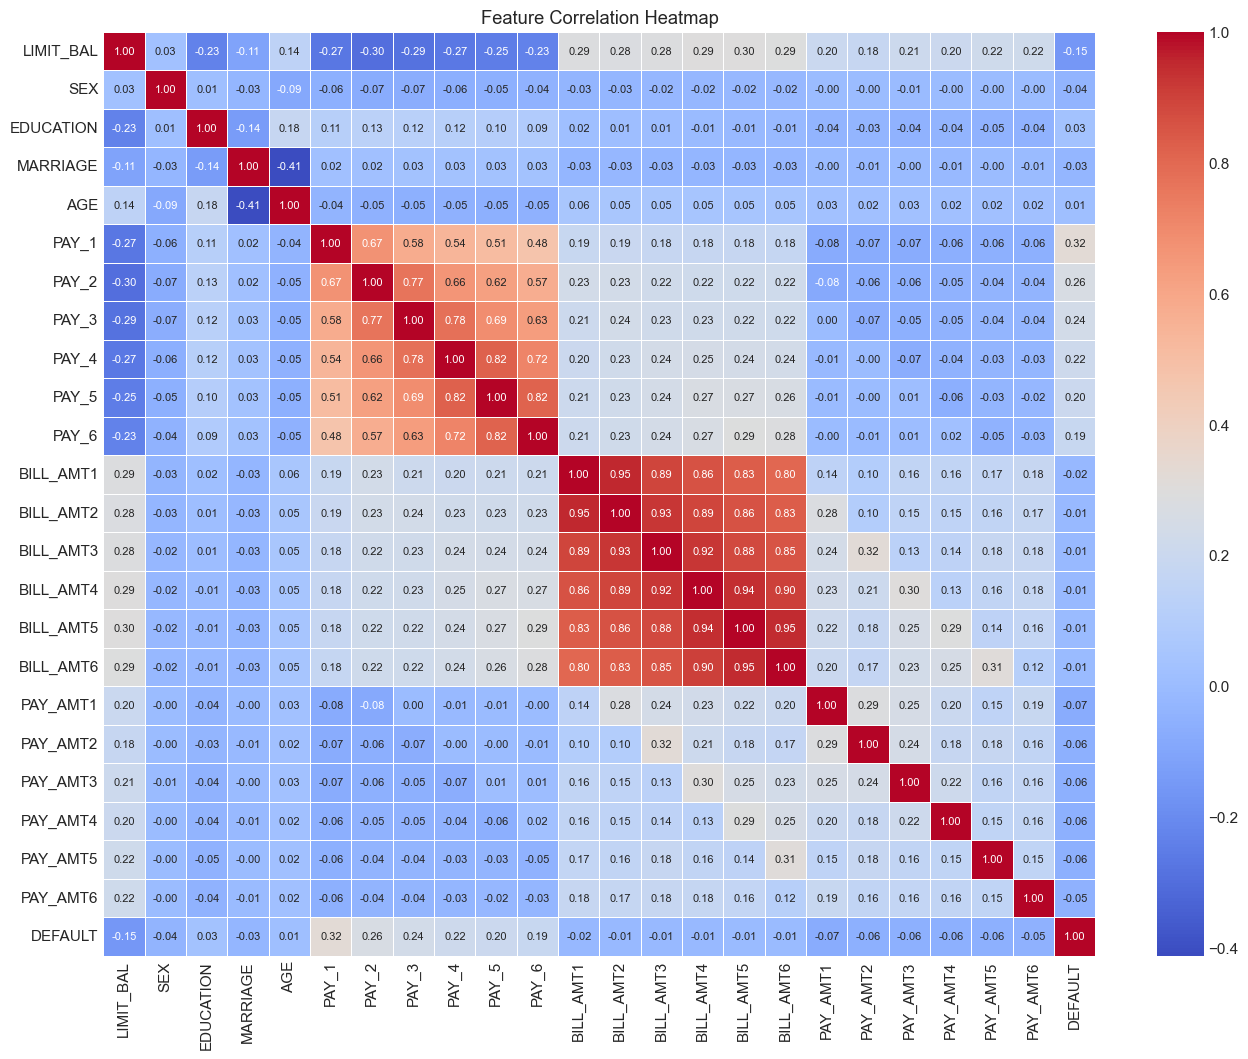

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DEFAULT', y='LIMIT_BAL', palette='Set2', ax=axes[0])
axes[0].set_title('Credit Limit (LIMIT_BAL) vs Default')

sns.countplot(data=df, x='PAY_1', hue='DEFAULT', palette='Set2', ax=axes[1])
axes[1].set_title('Recent Repayment Status (PAY_1) vs Default')

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, annot_kws={"size": 8})
plt.title('Feature Correlation Heatmap')
plt.show()

**Observations:**
* **Credit Limit & Outliers:** Defaulters generally have lower credit limits (`LIMIT_BAL`). Financial features contain high upper-bound outliers (wealthy clients), confirming the need for feature scaling (`StandardScaler`).
* **Strongest Predictor (`PAY_1`):** Repayment status in the most recent month (`PAY_1`) has the strongest positive correlation with `DEFAULT` (**0.32**). Clients with delayed payments (`PAY_1 >= 1`) have a drastically higher probability of default.
* **Multicollinearity:** Bill amount columns (`BILL_AMT1` to `BILL_AMT6`) are heavily correlated with each other ($r > 0.80$), and `PAY_1` to `PAY_6` show moderate-to-high correlation. This is critical to note when interpreting **Permutation Importance** and **Linear Coefficients** in Phase 4, as correlated features can share or dilute importance scores.

#### D. Summary Statistics & Bill/Payment Distributions
We display the descriptive statistics (`mean`, `std`, `min`, `max`) to inspect value ranges and check the skewness of bill and payment amounts.

,mean,std,min,50%,max
LIMIT_BAL,167442.01,129760.14,10000.0,140000.0,1000000.0
SEX,1.60,0.49,1.0,2.0,2.0
EDUCATION,1.84,0.74,1.0,2.0,4.0
MARRIAGE,1.56,0.52,1.0,2.0,3.0
AGE,35.49,9.22,21.0,34.0,79.0
PAY_1,-0.02,1.12,-2.0,0.0,8.0
PAY_2,-0.13,1.20,-2.0,0.0,8.0
PAY_3,-0.16,1.20,-2.0,0.0,8.0
PAY_4,-0.22,1.17,-2.0,0.0,8.0
PAY_5,-0.26,1.13,-2.0,0.0,8.0


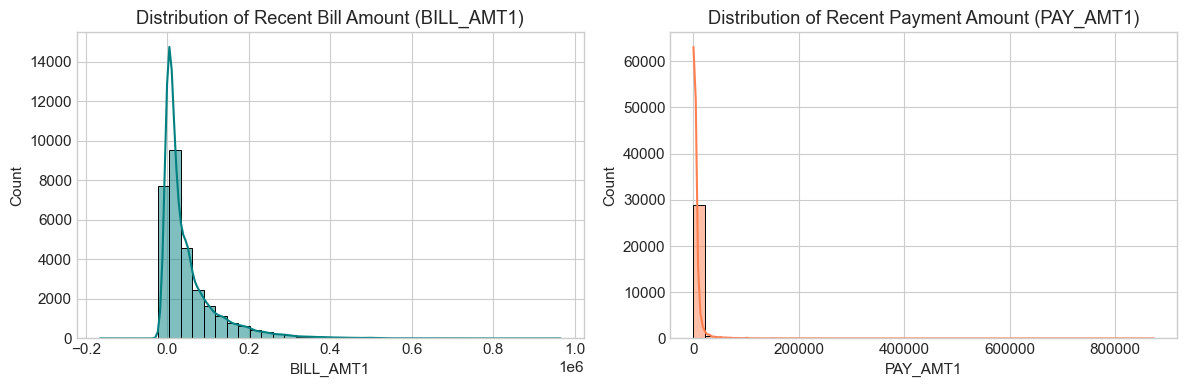

In [10]:
# 1. Summary statistics table (transposed for easy reading)
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))

# 2. Distribution of most recent Bill and Payment amounts
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['BILL_AMT1'], bins=40, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Recent Bill Amount (BILL_AMT1)')

sns.histplot(df['PAY_AMT1'], bins=40, kde=True, color='coral', ax=axes[1])
axes[1].set_title('Distribution of Recent Payment Amount (PAY_AMT1)')
plt.tight_layout()
plt.show()

**Observations:**
* **Scale Differences & Negative Bills:** Features vary wildly in scale (`AGE` ranges from `21` to `79`, while `LIMIT_BAL` reaches `1,000,000`), confirming that `StandardScaler` is mandatory. Minimum values in `BILL_AMT` are negative, which validly represents credit balances (overpayments).
* **Right Skewness:** Both `BILL_AMT1` and `PAY_AMT1` are heavily right-skewed, with most clients having moderate bills/payments and a few extreme high-value outliers.

### 1.4 Stratified Train/Test Split & Leak-Free Preprocessing Setup
We split the raw cleaned dataset into 80% training and 20% testing sets using `stratify=y` and a fixed random seed (`42`). To strictly prevent data leakage, both `OneHotEncoder` (for nominal features `SEX`, `EDUCATION`, `MARRIAGE`) and feature scalers are wrapped inside `sklearn` Pipelines so they are fitted **only on the training folds**.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 1. Separate features (X) and target (y) BEFORE any encoding
X = df.drop(columns=['DEFAULT'])
y = df['DEFAULT']

In [12]:
# 2. Stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [13]:
# 3. Reusable One-Hot Encoder (to be placed inside Pipelines)
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
encoder = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)],
    remainder='passthrough', #This means that the remaining numeric columns will be left unchanged
    verbose_feature_names_out=False
).set_output(transform='pandas')

In [14]:
print(f"Train shape: {X_train.shape} | Default rate: {y_train.mean()*100:.2f}%")
print(f"Test shape:  {X_test.shape}  | Default rate: {y_test.mean()*100:.2f}%")

Train shape: (23972, 23) | Default rate: 22.13%
Test shape:  (5993, 23)  | Default rate: 22.13%


**Preprocessing Summary:**
* Both training (`23,972` rows) and testing (`5,993` rows) sets maintain the exact same default ratio (**22.13%**), confirming a successful stratified split.
* Both **One-Hot Encoding and Feature Scaling** are intentionally deferred to `sklearn` Pipelines so they are fitted strictly on training folds with zero data leakage during cross-validation.

## Phase 2: Model Implementation & Hyperparameter Tuning
### 2.1 Cross-Validation Evaluation Function
To prevent test set leakage, all baseline comparisons and hyperparameter tuning are evaluated strictly on `X_train` using **5-Fold Stratified Cross-Validation**, reporting **mean ± standard deviation** across all five metrics. `X_test` is reserved strictly for final evaluation in Phase 3.

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_cv(name, model, X_train, y_train):
    scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    return {
        'Model': name,
        'Accuracy': f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        'Precision': f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        'Recall': f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        'F1-Score': f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        'ROC-AUC': f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}"
    }

### 2.2 Training Baseline Interpretable Models
We train our three interpretable baseline models (`Logistic Regression`, `Decision Tree`, and `Gaussian Naive Bayes`). `StandardScaler` is wrapped inside a `Pipeline` for models sensitive to feature scale, while `Decision Tree` uses the unscaled features directly for clearer rule interpretation.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

baseline_models = {
    'Logistic Regression': make_pipeline(
        encoder, StandardScaler(),
        LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE)
    ),
    'Decision Tree': make_pipeline(
        encoder,
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)
    ),
    'Naive Bayes': make_pipeline(
        encoder, StandardScaler(),
        GaussianNB()
    )
}

baseline_results = [evaluate_cv(name, model, X_train, y_train) for name, model in baseline_models.items()]
display(pd.DataFrame(baseline_results).sort_values(by='ROC-AUC', ascending=False))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Naive Bayes,0.5654 ± 0.0280,0.3080 ± 0.0142,0.7677 ± 0.0146,0.4393 ± 0.0121,0.7348 ± 0.0079
0,Logistic Regression,0.6861 ± 0.0064,0.3781 ± 0.0077,0.6488 ± 0.0223,0.4776 ± 0.0108,0.7257 ± 0.0108
1,Decision Tree,0.7284 ± 0.0040,0.3868 ± 0.0087,0.3890 ± 0.0105,0.3879 ± 0.0091,0.6069 ± 0.0058


**Baseline Results Analysis (5-Fold CV):**
* **Naive Bayes (`ROC-AUC: 0.7348 ± 0.0079`, `Recall: 0.7677 ± 0.0146`):** Achieved the highest Recall and ROC-AUC among the baselines, capturing most defaulters. However, its Precision (`0.3080`) and Accuracy (`0.5654`) are low because Gaussian Naive Bayes assumes feature independence and normal distributions, whereas our EDA revealed strong multicollinearity and heavy right-skewness.
* **Logistic Regression (`ROC-AUC: 0.7257 ± 0.0108`, `F1-Score: 0.4776 ± 0.0108`):** Delivered the best overall balance between Precision (`0.3781`) and Recall (`0.6488`), making it the strongest linear baseline.
* **Decision Tree (`ROC-AUC: 0.6069 ± 0.0058`, `F1-Score: 0.3879 ± 0.0091`):** Performed the worst on validation folds due to severe **overfitting**—without depth constraints (`max_depth=None`), the tree memorizes training noise rather than generalizing.

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

additional_models = {
    'KNN': make_pipeline(
        encoder,
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    'Random Forest': make_pipeline(
        encoder,
        RandomForestClassifier(
            n_estimators=100,
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),

    'Gradient Boosting': make_pipeline(
        encoder,
        GradientBoostingClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE
        )
    )
}

additional_results = [
    evaluate_cv(name, model, X_train, y_train)
    for name, model in additional_models.items()
]

display(
    pd.DataFrame(additional_results)
    .sort_values(by='ROC-AUC', ascending=False)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Gradient Boosting,0.8218 ± 0.0060,0.6795 ± 0.0260,0.3688 ± 0.0139,0.4780 ± 0.0167,0.7836 ± 0.0080
1,Random Forest,0.8142 ± 0.0048,0.6499 ± 0.0226,0.3482 ± 0.0075,0.4534 ± 0.0109,0.7655 ± 0.0067
0,KNN,0.7911 ± 0.0048,0.5457 ± 0.0201,0.3386 ± 0.0078,0.4177 ± 0.0076,0.7012 ± 0.0040


### 2.3 Hyperparameter Tuning (Gradient Boosting)

We use RandomizedSearchCV with 5-Fold Stratified Cross-Validation to search for the best Gradient Boosting hyperparameters using the training data.

In [18]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline

# Build the Gradient Boosting pipeline
gb_pipeline = make_pipeline(
    encoder,
    GradientBoostingClassifier(random_state=RANDOM_STATE)
)

# Define the hyperparameter search space
param_grid = {
    'gradientboostingclassifier__n_estimators': [100, 150, 200, 300],
    'gradientboostingclassifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'gradientboostingclassifier__max_depth': [2, 3, 4, 5],
    'gradientboostingclassifier__min_samples_split': [2, 5, 10],
    'gradientboostingclassifier__min_samples_leaf': [1, 2, 5],
    'gradientboostingclassifier__subsample': [0.8, 1.0]
}

# Define Stratified 5-Fold Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Perform Randomized Search
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='accuracy',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

# Fit the search using training data
gb_search.fit(X_train, y_train)

# Display the best parameters
print("Best Parameters:")
print(gb_search.best_params_)

print("\nBest CV Accuracy:")
print(f"{gb_search.best_score_ * 100:.2f}%")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'gradientboostingclassifier__subsample': 0.8, 'gradientboostingclassifier__n_estimators': 100, 'gradientboostingclassifier__min_samples_split': 2, 'gradientboostingclassifier__min_samples_leaf': 1, 'gradientboostingclassifier__max_depth': 4, 'gradientboostingclassifier__learning_rate': 0.05}

Best CV Accuracy:
82.18%


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Collect all trained model candidates
final_models = {
    **baseline_models,
    **additional_models,
    'Gradient Boosting (Tuned)': gb_search.best_estimator_
}

# Store final test results
final_results = []

for name, model in final_models.items():

    # Fit model on the full training set
    model.fit(X_train, y_train)

    # Predict labels
    y_pred = model.predict(X_test)

    # Predict probabilities for ROC-AUC
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate test metrics
    final_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision': precision_score(y_test, y_pred, zero_division=0) * 100,
        'Recall': recall_score(y_test, y_pred, zero_division=0) * 100,
        'F1-Score': f1_score(y_test, y_pred, zero_division=0) * 100,
        'ROC-AUC': roc_auc_score(y_test, y_prob) * 100
    })

# Create and display results table
final_results_df = pd.DataFrame(final_results)

display(
    final_results_df
    .sort_values(by='ROC-AUC', ascending=False)
    .round(2)
    .reset_index(drop=True)
)

  File "c:\Users\Asus\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Asus\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Asus\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Asus\anaconda3\Lib\subprocess.py",

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,81.83,66.57,35.90,46.64,77.30
1,Gradient Boosting (Tuned),81.98,67.52,35.75,46.75,77.17
2,Random Forest,81.09,63.73,33.79,44.16,75.64
3,Naive Bayes,56.08,30.46,76.77,43.62,72.92
4,Logistic Regression,68.35,37.31,63.27,46.94,71.92
5,KNN,79.43,55.65,34.54,42.62,69.86
6,Decision Tree,72.50,38.20,39.29,38.74,60.63
